## Model Building & Evaluation

### Import Libraries and Load Cleaned Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)


# models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# utility functions
from utils import evaluate_model, plot_confusion_matrix, plot_roc_curves, compare_models

sns.set_theme(style="whitegrid")
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [2]:
# import cleaned dataset from from notebook 2
data = pd.read_csv("Data/titanic_cleaned.csv")
print("Data Shape:", data.shape)
data.head(10)

Data Shape: (891, 23)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
0,0,3,0,22.0,1,0,7.2500,0,2,0,...,1,0,0,0,1,0,0,0,0,0
1,1,1,1,38.0,1,0,71.2833,1,2,0,...,0,1,0,0,0,1,0,0,0,1
2,1,3,1,26.0,0,0,7.9250,0,1,1,...,0,0,0,0,1,0,0,1,0,0
3,1,1,1,35.0,1,0,53.1000,1,2,0,...,0,1,0,0,1,0,0,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,1,1,...,1,0,0,0,1,0,0,1,0,0
5,0,3,0,25.0,0,0,8.4583,0,1,1,...,1,0,0,0,1,0,0,1,0,0
6,0,1,0,54.0,0,0,51.8625,1,1,1,...,1,0,0,0,0,1,0,0,0,1
7,0,3,0,2.0,3,1,21.0750,0,5,0,...,0,0,0,0,0,0,0,0,1,0
8,1,3,1,27.0,0,2,11.1333,0,3,0,...,0,1,0,0,1,0,0,1,0,0
9,1,2,1,14.0,1,0,30.0708,0,2,0,...,0,1,0,1,0,0,0,0,1,0


### Prepare Features and Target

In [3]:
# seprate features and taget
X = data.drop(columns=["Survived"])
y = data["Survived"]

print(f"Features shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")
print(f"\nFeature columns: {X.columns.tolist()}")

Features shape: (891, 22)
Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Feature columns: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'IsAlone', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'AgeGroup_Teen', 'AgeGroup_Young Adult', 'AgeGroup_Adult', 'AgeGroup_Senior', 'FareBin_Medium', 'FareBin_High', 'FareBin_Very High']


In [4]:
# Train/test split (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y) 


print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nTraining survival rate: {y_train.mean():.2%}")
print(f"Test survival rate: {y_test.mean():.2%}")

Training set: 623 samples
Test set: 268 samples

Training survival rate: 38.36%
Test survival rate: 38.43%


In [5]:
# Feature scaling — important for KNN, SVM, and Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for readability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Scaling complete. First 3 rows of scaled training data:")
X_train_scaled.head(3)

Scaling complete. First 3 rows of scaled training data:


,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_Q,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
748,-1.589202,-0.731083,-0.782506,0.562957,-0.448665,0.465738,1.892322,0.110685,-1.284937,-0.304930,...,0.843527,-0.413585,-0.182119,-0.279024,0.871715,-0.595271,-0.15707,-0.590326,-0.577968,1.815641
45,0.819734,-0.731083,-0.332603,-0.474682,-0.448665,-0.478269,-0.528451,-0.558800,0.778248,-0.304930,...,0.843527,-0.413585,-0.182119,-0.279024,0.871715,-0.595271,-0.15707,1.693979,-0.577968,-0.550770
28,0.819734,1.367833,-0.595047,-0.474682,-0.448665,-0.481848,-0.528451,-0.558800,0.778248,3.279439,...,-1.185498,-0.413585,-0.182119,-0.279024,0.871715,-0.595271,-0.15707,-0.590326,-0.577968,-0.550770


### Train Models

In [6]:
# Store results for comparison
results = []
trained_models = {}

#### Logistic Regression


  Logistic Regression Results
  Accuracy:  0.8396
  Precision: 0.7778
  Recall:    0.8155
  F1 Score:  0.7962

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.87       165
           1       0.78      0.82      0.80       103

    accuracy                           0.84       268
   macro avg       0.83      0.84      0.83       268
weighted avg       0.84      0.84      0.84       268



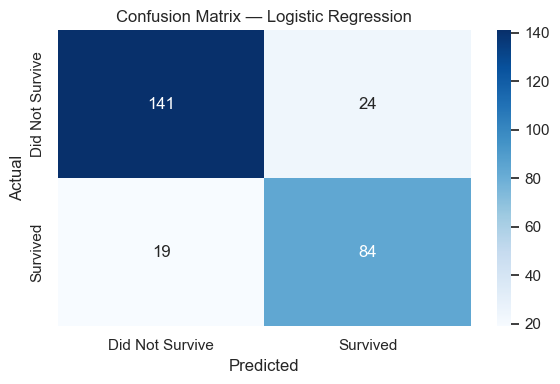

In [7]:
lr = LogisticRegression(random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
metrics_lr = evaluate_model(y_test, y_pred_lr, "Logistic Regression")
results.append(metrics_lr)
trained_models["Logistic Regression"] = lr

plot_confusion_matrix(y_test, y_pred_lr, "Logistic Regression")

#### Decision Tree


  Decision Tree Results
  Accuracy:  0.8172
  Precision: 0.7288
  Recall:    0.8350
  F1 Score:  0.7783

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.81      0.84       165
           1       0.73      0.83      0.78       103

    accuracy                           0.82       268
   macro avg       0.81      0.82      0.81       268
weighted avg       0.83      0.82      0.82       268



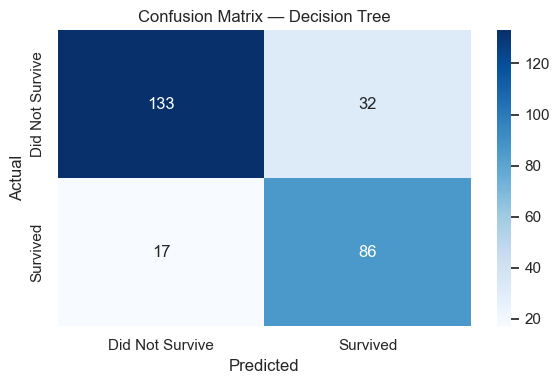

In [8]:
dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
metrics_dt = evaluate_model(y_test, y_pred_dt, "Decision Tree")
results.append(metrics_dt)
trained_models["Decision Tree"] = dt

plot_confusion_matrix(y_test, y_pred_dt, "Decision Tree")

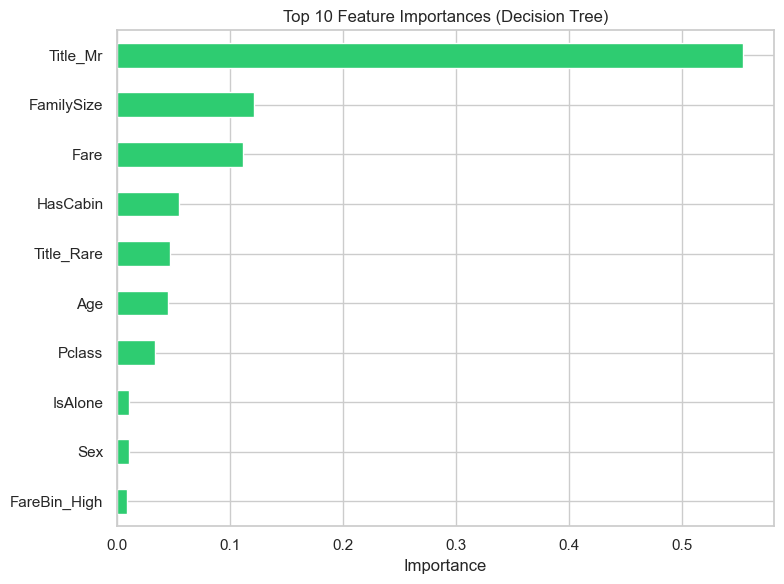

In [9]:
# Feature importance from Decision Tree
feature_imp = pd.Series(dt.feature_importances_, index=X_train.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8,6))
feature_imp.tail(10).plot(kind="barh", ax=ax, color="#2ecc71")
ax.set_title("Top 10 Feature Importances (Decision Tree)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

#### Random Forest


  Random Forest Results
  Accuracy:  0.8022
  Precision: 0.7841
  Recall:    0.6699
  F1 Score:  0.7225

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.85       165
           1       0.78      0.67      0.72       103

    accuracy                           0.80       268
   macro avg       0.80      0.78      0.78       268
weighted avg       0.80      0.80      0.80       268



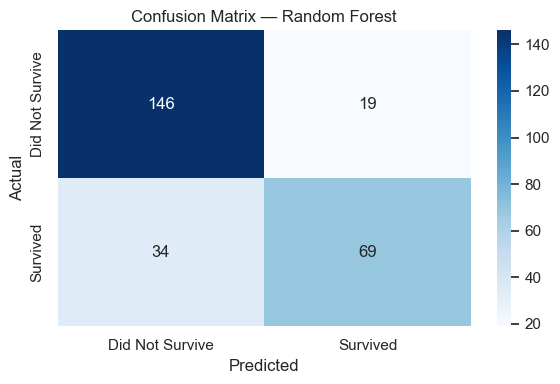

In [10]:
rf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=7)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
metrics_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")
results.append(metrics_rf)
trained_models["Random Forest"] = rf

plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")

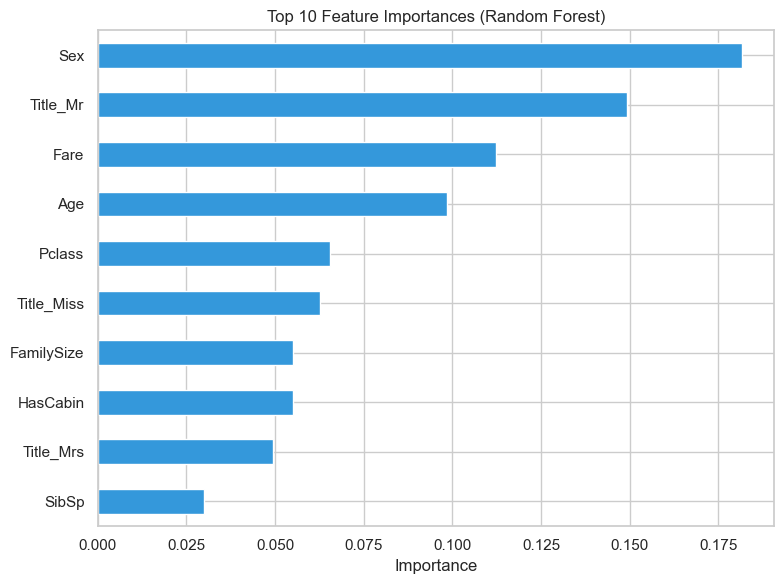

In [11]:
# Feature importance from Random Forest
feature_imp_rf = pd.Series(rf.feature_importances_, index=X_train.columns)
feature_imp_rf = feature_imp_rf.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp_rf.tail(10).plot(kind="barh", ax=ax, color="#3498db")
ax.set_title("Top 10 Feature Importances (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


  K-Nearest Neighbors Results
  Accuracy:  0.7724
  Precision: 0.7500
  Recall:    0.6117
  F1 Score:  0.6738

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.87      0.83       165
           1       0.75      0.61      0.67       103

    accuracy                           0.77       268
   macro avg       0.77      0.74      0.75       268
weighted avg       0.77      0.77      0.77       268



  File "C:\Users\Manoj Shah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^

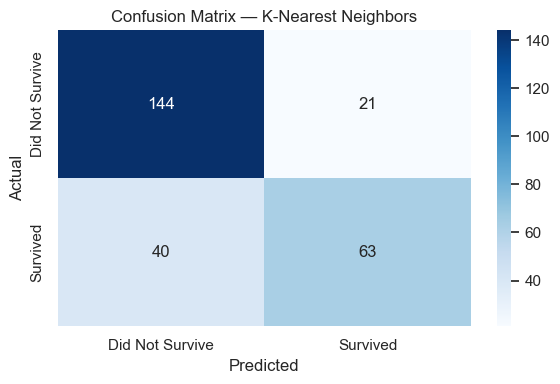

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
metrics_knn = evaluate_model(y_test, y_pred_knn, "K-Nearest Neighbors")
results.append(metrics_knn)
trained_models["K-Nearest Neighbors"] = knn

plot_confusion_matrix(y_test, y_pred_knn, "K-Nearest Neighbors")

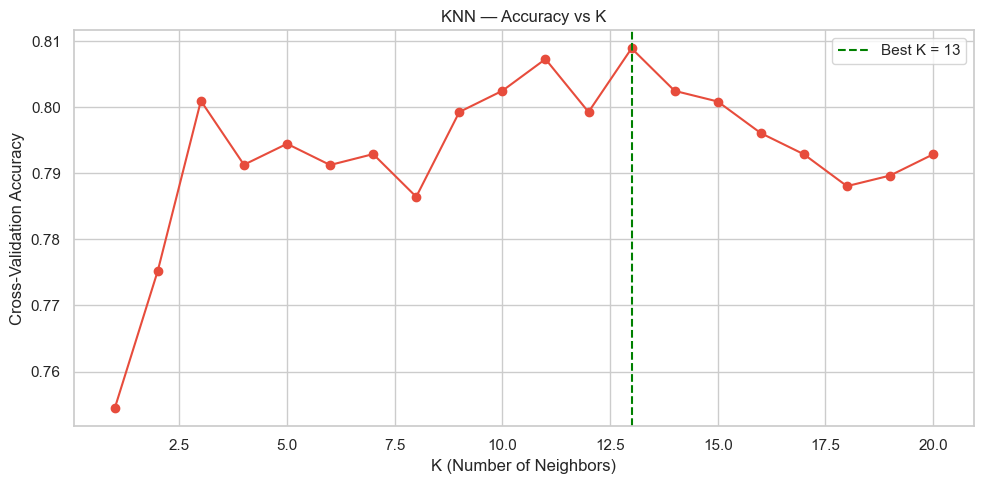

Best K: 13 with accuracy: 0.8089


In [13]:
# Find optimal K using cross-validation
k_range = range(1, 21)
k_scores = []

for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring="accuracy")
    k_scores.append(scores.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, k_scores, marker="o", color="#e74c3c")
ax.set_title("KNN — Accuracy vs K")
ax.set_xlabel("K (Number of Neighbors)")
ax.set_ylabel("Cross-Validation Accuracy")
best_k = list(k_range)[np.argmax(k_scores)]
ax.axvline(x=best_k, color="green", linestyle="--", label=f"Best K = {best_k}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Best K: {best_k} with accuracy: {max(k_scores):.4f}")

#### Support Vector Machine (SVM)


  Support Vector Machine Results
  Accuracy:  0.8134
  Precision: 0.7789
  Recall:    0.7184
  F1 Score:  0.7475

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       165
           1       0.78      0.72      0.75       103

    accuracy                           0.81       268
   macro avg       0.81      0.80      0.80       268
weighted avg       0.81      0.81      0.81       268



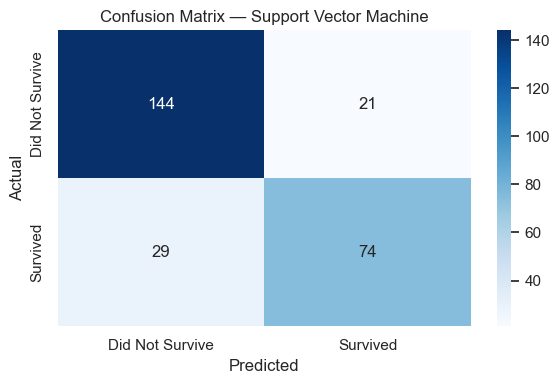

In [14]:
svm = SVC(kernel="rbf", probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
metrics_svm = evaluate_model(y_test, y_pred_svm, "Support Vector Machine")
results.append(metrics_svm)
trained_models["Support Vector Machine"] = svm

plot_confusion_matrix(y_test, y_pred_svm, "Support Vector Machine")

#### Gradient Boosting


  Gradient Boosting Results
  Accuracy:  0.8060
  Precision: 0.7931
  Recall:    0.6699
  F1 Score:  0.7263

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       165
           1       0.79      0.67      0.73       103

    accuracy                           0.81       268
   macro avg       0.80      0.78      0.79       268
weighted avg       0.80      0.81      0.80       268



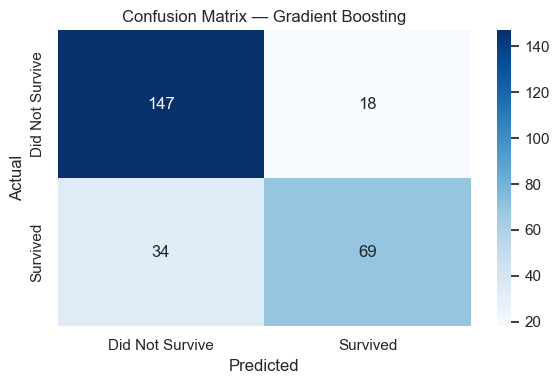

In [15]:
gb = GradientBoostingClassifier(random_state=42, n_estimators=100, learning_rate=0.1, max_depth=3)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
metrics_gb = evaluate_model(y_test, y_pred_gb, "Gradient Boosting")
results.append(metrics_gb)
trained_models["Gradient Boosting"] = gb

plot_confusion_matrix(y_test, y_pred_gb, "Gradient Boosting")

#### Gaussian Naive Bayes


  Naive Bayes Results
  Accuracy:  0.7873
  Precision: 0.6949
  Recall:    0.7961
  F1 Score:  0.7421

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.78      0.82       165
           1       0.69      0.80      0.74       103

    accuracy                           0.79       268
   macro avg       0.78      0.79      0.78       268
weighted avg       0.80      0.79      0.79       268



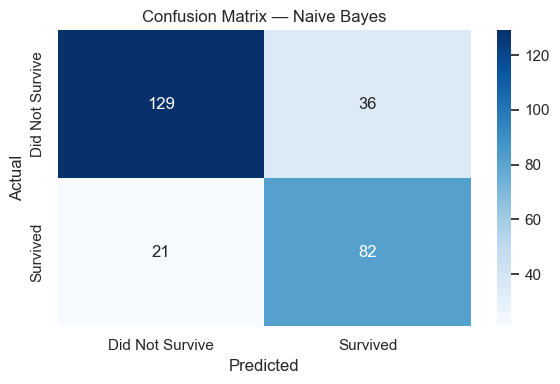

In [16]:
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_pred_nb = nb.predict(X_test_scaled)
metrics_nb = evaluate_model(y_test, y_pred_nb, "Naive Bayes")
results.append(metrics_nb)
trained_models["Naive Bayes"] = nb

plot_confusion_matrix(y_test, y_pred_nb, "Naive Bayes")

#### Voting Classifier


  Soft Voting Classifier Results
  Accuracy:  0.8097
  Precision: 0.7321
  Recall:    0.7961
  F1 Score:  0.7628

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.82      0.84       165
           1       0.73      0.80      0.76       103

    accuracy                           0.81       268
   macro avg       0.80      0.81      0.80       268
weighted avg       0.81      0.81      0.81       268



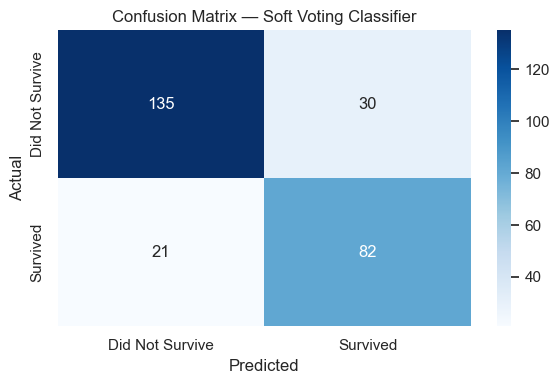

In [19]:
voting_classifier = VotingClassifier(
    estimators=[
        ('lr', trained_models['Logistic Regression']),
        ('dt', trained_models['Decision Tree']),
        ('nb', trained_models['Naive Bayes']),
        ('svm', trained_models['Support Vector Machine'])
    ],
    voting='soft'
)

voting_classifier.fit(X_train_scaled, y_train)

y_pred_voting = voting_classifier.predict(X_test_scaled)

metrics_voting = evaluate_model(y_test, y_pred_voting, "Soft Voting Classifier")

results.append(metrics_voting)
trained_models["Soft Voting Classifier"] = voting_classifier

plot_confusion_matrix(y_test, y_pred_voting, "Soft Voting Classifier")

#### Model Comparison

In [23]:
# Compare all models
comparison_df = compare_models(results)
comparison_df.style.background_gradient(cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1 Score"])

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.839552,0.777778,0.815534,0.796209
1,Decision Tree,0.817164,0.728814,0.834951,0.778281
2,Soft Voting Classifier,0.809701,0.732143,0.796117,0.762791
3,Support Vector Machine,0.813433,0.778947,0.718447,0.747475
4,Naive Bayes,0.787313,0.694915,0.796117,0.742081
5,Gradient Boosting,0.805970,0.793103,0.669903,0.726316
6,Random Forest,0.802239,0.784091,0.669903,0.722513
7,K-Nearest Neighbors,0.772388,0.750000,0.611650,0.673797


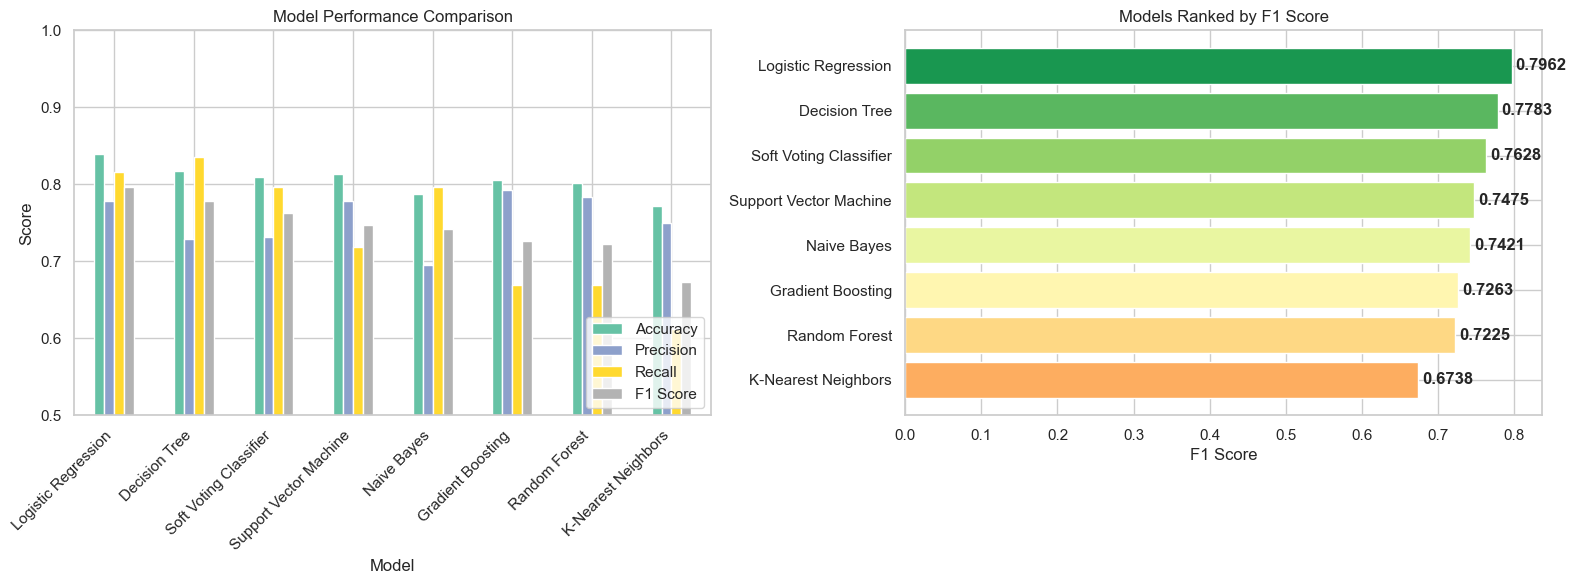

In [24]:
# Visualize model comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart of all metrics
comparison_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", ax=axes[0], colormap="Set2"
)
axes[0].set_title("Model Performance Comparison")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.5, 1.0)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].legend(loc="lower right")

# F1 Score ranking
sorted_df = comparison_df.sort_values("F1 Score", ascending=True)
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(sorted_df)))
axes[1].barh(sorted_df["Model"], sorted_df["F1 Score"], color=colors)
axes[1].set_title("Models Ranked by F1 Score")
axes[1].set_xlabel("F1 Score")
for i, v in enumerate(sorted_df["F1 Score"]):
    axes[1].text(v + 0.005, i, f"{v:.4f}", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

#### Cross-Validation

In [27]:
# Cross-validation for all models (5-fold)
cv_results = {}

models_for_cv = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, max_depth=7),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42, probability=True),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=3),
    "Naive Bayes": GaussianNB(),
    "Soft Voting Classifier": VotingClassifier(
        estimators=[
            ('lr', LogisticRegression(random_state=42, max_iter=1000)),
            ('dt', DecisionTreeClassifier(random_state=42, max_depth=5)),
            ('nb', GaussianNB()),
            ('svm', SVC(kernel="rbf", random_state=42, probability=True))
        ],
        voting='soft'
    )
}

print("5-Fold Cross-Validation Results:")
print("=" * 55)
for name, model in models_for_cv.items():
    # Use scaled data for models that need it
    if name in ["Logistic Regression","KNN","SVM","Naive Bayes","Soft Voting Classifier"]:
        scores = cross_val_score(model, X_train_scaled, y_train,cv=5, scoring="accuracy")
    else:
        scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_results[name] = scores
    print(f"{name:25s} — Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")

5-Fold Cross-Validation Results:
Logistic Regression       — Mean: 0.8266 (+/- 0.0182)
Decision Tree             — Mean: 0.8058 (+/- 0.0328)
Random Forest             — Mean: 0.8330 (+/- 0.0241)
KNN                       — Mean: 0.7945 (+/- 0.0327)
SVM                       — Mean: 0.8073 (+/- 0.0261)
Gradient Boosting         — Mean: 0.8379 (+/- 0.0131)
Naive Bayes               — Mean: 0.7704 (+/- 0.0303)
Soft Voting Classifier    — Mean: 0.8105 (+/- 0.0350)


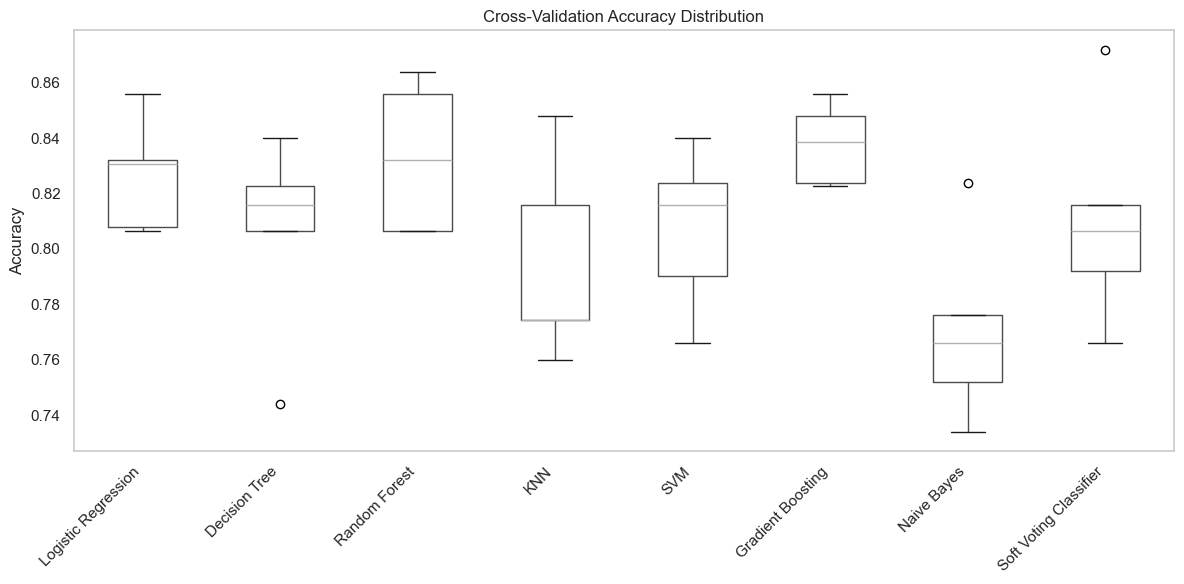

In [28]:
# Box plot of cross-validation scores
fig, ax = plt.subplots(figsize=(12, 6))
cv_df = pd.DataFrame(cv_results)
cv_df.boxplot(ax=ax, grid=False)
ax.set_title("Cross-Validation Accuracy Distribution")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### ROC Curve Comparison

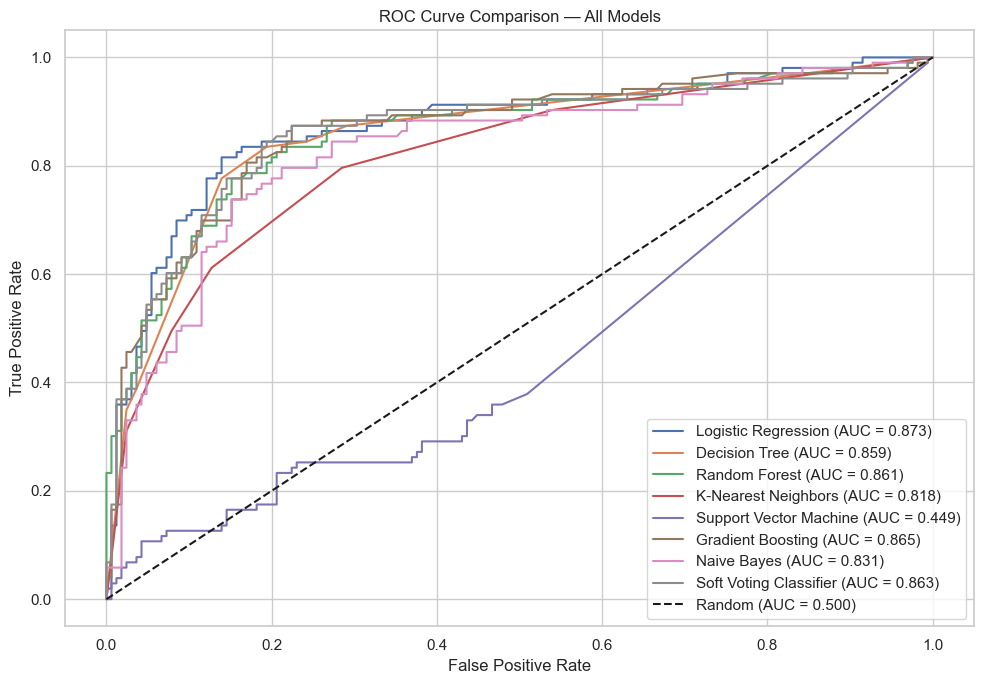

In [29]:
# Plot ROC curves for all models
# Note: KNN, SVM, LR, NB use scaled data; DT, RF, GB use unscaled
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():
    # Choose the right test data
    if name in ["Logistic Regression", "K-Nearest Neighbors", "SVM", "Naive Bayes","Soft Voting Classifier"]:
        X_eval = X_test_scaled
    else:
        X_eval = X_test
    
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_eval)[:, 1]
    else:
        y_prob = model.decision_function(X_eval)
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — All Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### Hyperparameter Tuning — Random Forest

In [30]:
# Define hyperparameter grid
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best CV F1 score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits

Best parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}
Best CV F1 score: 0.7891



  Tuned Random Forest Results
  Accuracy:  0.8209
  Precision: 0.7895
  Recall:    0.7282
  F1 Score:  0.7576

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       165
           1       0.79      0.73      0.76       103

    accuracy                           0.82       268
   macro avg       0.81      0.80      0.81       268
weighted avg       0.82      0.82      0.82       268



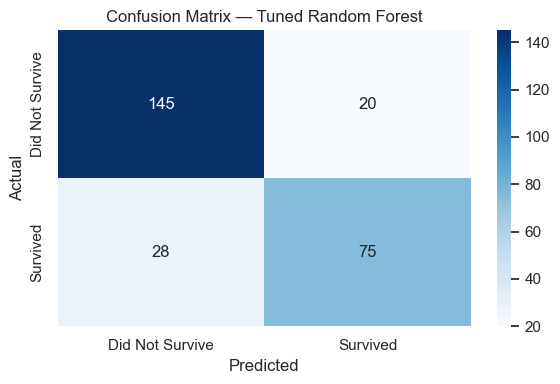

In [31]:
# Evaluate tuned model
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

metrics_tuned = evaluate_model(y_test, y_pred_tuned, "Tuned Random Forest")
plot_confusion_matrix(y_test, y_pred_tuned, "Tuned Random Forest")

#### Feature Importance — Final Model

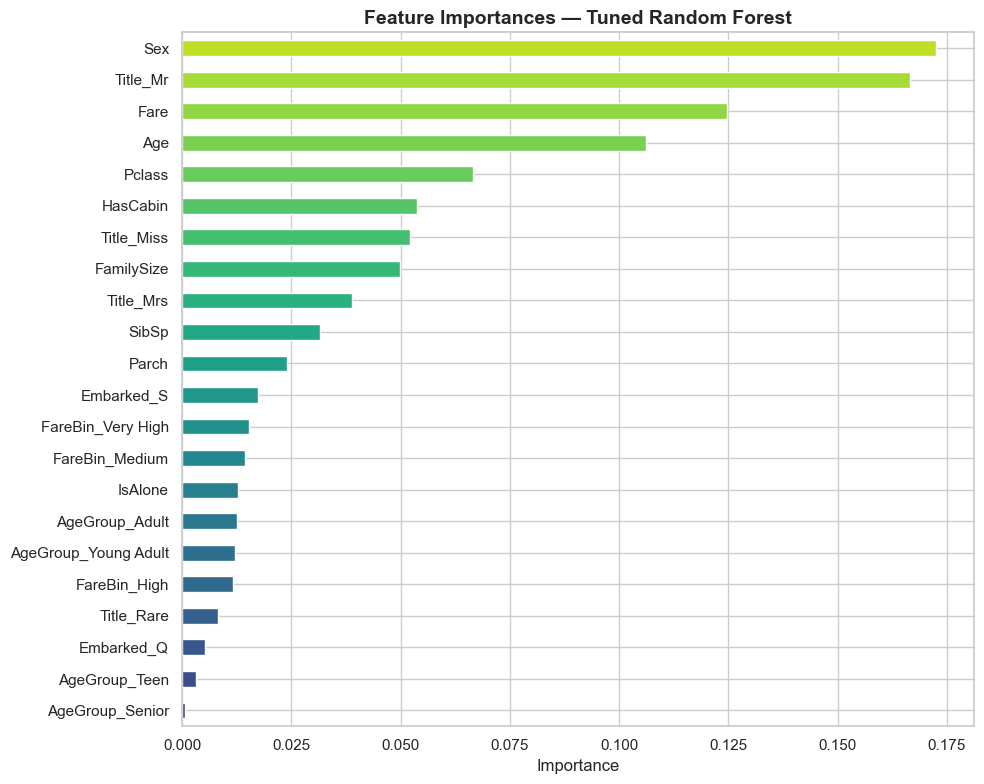


Top 5 most important features:
Pclass      0.066504
Age         0.106063
Fare        0.124736
Title_Mr    0.166617
Sex         0.172559
dtype: float64


In [32]:
# Feature importance from the tuned model
feature_imp_final = pd.Series(best_rf.feature_importances_, index=X_train.columns)
feature_imp_final = feature_imp_final.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(feature_imp_final)))
feature_imp_final.plot(kind="barh", ax=ax, color=colors)
ax.set_title("Feature Importances — Tuned Random Forest", fontsize=14, fontweight="bold")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nTop 5 most important features:")
print(feature_imp_final.tail(5))

#### Make Predictions on New Data

In [33]:
# Example: Predict survival for a new passenger
# Create a sample with the same features as our training data
sample_passenger = pd.DataFrame([{
    col: 0 for col in X_train.columns
}])

# 25-year-old female in 1st class, traveling alone, fare $100, embarked at Cherbourg
sample_passenger["Pclass"] = 1
sample_passenger["Sex"] = 1  # female
sample_passenger["Age"] = 25
sample_passenger["Fare"] = 100
sample_passenger["FamilySize"] = 1
sample_passenger["IsAlone"] = 1
sample_passenger["HasCabin"] = 1

prediction = best_rf.predict(sample_passenger)[0]
probability = best_rf.predict_proba(sample_passenger)[0]

print("Sample Passenger: 25-year-old female, 1st class, solo traveler")
print(f"Prediction: {'Survived' if prediction == 1 else 'Did Not Survive'}")
print(f"Probability — Did Not Survive: {probability[0]:.2%}")
print(f"Probability — Survived: {probability[1]:.2%}")

Sample Passenger: 25-year-old female, 1st class, solo traveler
Prediction: Survived
Probability — Did Not Survive: 8.21%
Probability — Survived: 91.79%


###  Final Summary

#### Model Performance Summary

In [34]:
# Final comparison including tuned model
all_results = results + [metrics_tuned]
final_df = compare_models(all_results)
final_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.839552,0.777778,0.815534,0.796209
1,Decision Tree,0.817164,0.728814,0.834951,0.778281
2,Soft Voting Classifier,0.809701,0.732143,0.796117,0.762791
3,Tuned Random Forest,0.820896,0.789474,0.728155,0.757576
4,Support Vector Machine,0.813433,0.778947,0.718447,0.747475
5,Naive Bayes,0.787313,0.694915,0.796117,0.742081
6,Gradient Boosting,0.805970,0.793103,0.669903,0.726316
7,Random Forest,0.802239,0.784091,0.669903,0.722513
8,K-Nearest Neighbors,0.772388,0.750000,0.611650,0.673797


## Key Takeaways

1. **Sex, Fare, and Pclass** were the most important features for predicting survival.
2. **Ensemble methods** (Random Forest, Gradient Boosting) generally outperformed simpler models.
3. **Feature engineering** (Title, FamilySize, HasCabin) provided meaningful signal.
4. **Hyperparameter tuning** with GridSearchCV improved the Random Forest model.
5. **Cross-validation** helped us assess model stability and avoid overfitting.

## What to Try Next

- Try XGBoost or LightGBM for potentially better performance.
- Experiment with different feature combinations.
- Try ensemble stacking (combining multiple models).
- Submit predictions to the Kaggle Titanic competition.